# TGLF default width search vs GS2: growth-rate bias on the KBM hypercubes

Fusion_PhD-qp5.30 (talk figure, advisory). Does TGLF's default width search (FIND_WIDTH T, NBASIS_MIN 2, search 0.3-1.65,
FILTER 2) systematically over-predict the GS2 growth rate? Contrast: fixed WIDTH 1.92 at NBASIS_MAX 4, same samples.

- Data, no new runs: `TGLF/Runs/kbm_tglf_find_width/<db>/fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65` (search arm; **NBASIS_MAX 32**, since no
  leaf at TGLF's default NBASIS_MAX 4 exists) and `TGLF/Runs/kbm_tglf_nbasis/<db>/nb4_nx32_fp2p0_w1p9218` (fixed arm), both Fusion_PhD-qp5.21.
- GS2: `pyro_cube_avg` tail average, population = GS2-KBM by the user classifier (`mode_classification`), as qp5.21.
- Bias statistic: $r = \log_{10}(\gamma_{\rm TGLF}/\gamma_{\rm GS2})$ over cases with TGLF $\gamma>0$; cases where TGLF finds no unstable mode ($\gamma=0$) are
  counted separately and kept in LogMed $|\gamma-\gamma_{\rm GS2}| = \log_{10}\,\mathrm{median}\,|\gamma_{\rm TGLF}-\gamma_{\rm GS2}|$ (a miss contributes $\gamma_{\rm GS2}$).

In [1]:
from pathlib import Path
import os, json, re, warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyrokinetics
from pyrokinetics import PyroHypercube
from general_analysis import mode_classification as mc

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)
warnings.filterwarnings("ignore")
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
databases = ["SPR-045", "M1"]
colour = {"SPR-045": "tab:blue", "M1": "tab:orange"}
width_fixed = 1.9218                      # qp5.21 common window 1.9-2.8 at NBASIS_MAX 4
rng = np.random.default_rng(0)

/pitagora_work/FUPB2_QLTURB/fwatts/ga-wt-qp530/.venv/lib/python3.14/site-packages/xrft/xrft.py:289: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  daft = \mathbb{F}(da - \overline{da})
/pitagora_work/FUPB2_QLTURB/fwatts/ga-wt-qp530/.venv/lib/python3.14/site-packages/xrft/xrft.py:496: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  da = \mathbb{F}(daft - \overline{daft})
/pitagora_work/FUPB2_QLTURB/fwatts/ga-wt-qp530/.venv/lib/python3.14/site-packages/xrft/xrft.py:695: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  da' = da - \overline{da}
/pitagora_work/FUPB2_QLTURB/fwatts/ga-wt-qp530/.venv/lib/python3.14/site-packages/xrft/xrft.py:800: SyntaxWarning: "\o" is an invalid escape sequence.

pyrokinetics 0.9.2.dev153+g3290c692


In [2]:
gs2, tglf_search, tglf_fixed = {}, {}, {}
for database in databases:
    gs2_dir = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE" / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gs2_avg = gs2_avg_scan.gk_output.data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_scan.gk_output.data.sample_name.values.astype(str) == names).all()
    label = np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data)))
    gamma_gs2 = gs2_avg.growth_rate.pint.dequantify().values.ravel()
    kbm = (label == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0)
    gs2[database] = dict(names=names[kbm], gamma=gamma_gs2[kbm], units=str(gs2_avg.growth_rate.data.units))
    print(database, "GS2-KBM:", kbm.sum())

    for store, leaf in ((tglf_search, data_root / "TGLF/Runs/kbm_tglf_find_width" / database / "fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65"),
                        (tglf_fixed, data_root / "TGLF/Runs/kbm_tglf_nbasis" / database / "nb4_nx32_fp2p0_w1p9218")):
        tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
        tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
        flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]   # settings GyroRun put on the source deck
        print(database, leaf.name, {k: flags[k] for k in ("FIND_WIDTH", "NBASIS_MIN", "NBASIS_MAX", "NXGRID", "FILTER", "WIDTH") if k in flags})
        tglf = tglf_scan.gk_output.data.set_index(sample="sample_name").sel(sample=gs2[database]["names"])
        assert str(tglf.growth_rate.data.units) == re.sub(r"_pyroscan_base\d+", "", gs2[database]["units"]), "normalisations differ"
        growth = tglf.growth_rate.pint.dequantify()
        assert int(tglf_scan.base_pyro.gk_input.data["ibranch"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()  # mode 0 = dominant
        store[database] = dict(gamma=growth.isel(mode=0).clip(min=0).values)
        if "gaussian_width" in tglf:
            store[database]["width"] = tglf.gaussian_width.pint.dequantify().values

SPR-045 GS2-KBM: 119


SPR-045 fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65 {'FIND_WIDTH': True, 'NBASIS_MIN': 2, 'NBASIS_MAX': 32, 'NXGRID': 32, 'FILTER': 2.0, 'WIDTH': 1.65}


SPR-045 nb4_nx32_fp2p0_w1p9218 {'NBASIS_MAX': 4, 'NXGRID': 32, 'FILTER': 2.0}


M1 GS2-KBM: 161


M1 fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65 {'FIND_WIDTH': True, 'NBASIS_MIN': 2, 'NBASIS_MAX': 32, 'NXGRID': 32, 'FILTER': 2.0, 'WIDTH': 1.65}


M1 nb4_nx32_fp2p0_w1p9218 {'NBASIS_MAX': 4, 'NXGRID': 32, 'FILTER': 2.0}


In [3]:
def bias_stats(gamma_tglf, gamma_gs2, n_boot=10000):
    found = gamma_tglf > 0
    ratio_log = np.log10(gamma_tglf[found] / gamma_gs2[found])
    boot = [np.median(rng.choice(ratio_log, ratio_log.size)) for _ in range(n_boot)]
    return dict(n=gamma_tglf.size, n_found=int(found.sum()), n_miss=int((~found).sum()),
                frac_above=float((ratio_log > 0).mean()), median_log_ratio=float(np.median(ratio_log)),
                ci_lo=float(np.percentile(boot, 2.5)), ci_hi=float(np.percentile(boot, 97.5)),
                mean_ratio=float((gamma_tglf[found] / gamma_gs2[found]).mean()),
                logmed_abs_err=float(np.log10(np.median(np.abs(gamma_tglf - gamma_gs2)))))

arms = {"TGLF default width search\n(FIND_WIDTH, NBASIS_MIN 2, 0.3-1.65, NBASIS_MAX 32)": tglf_search,
        f"TGLF fixed WIDTH {width_fixed:.2f}, NBASIS_MAX 4": tglf_fixed}
rows = []
for arm, store in arms.items():
    pooled_t = np.concatenate([store[d]["gamma"] for d in databases]); pooled_g = np.concatenate([gs2[d]["gamma"] for d in databases])
    for name, t, g in [*[(d, store[d]["gamma"], gs2[d]["gamma"]) for d in databases], ("both", pooled_t, pooled_g)]:
        rows.append(dict(arm=arm.split("\n")[0], population=name, **bias_stats(t, g)))
summary = pd.DataFrame(rows)
print(summary.round(3).to_string())

                                   arm population    n  n_found  n_miss  frac_above  median_log_ratio  ci_lo  ci_hi  mean_ratio  logmed_abs_err
0            TGLF default width search    SPR-045  119      116       3       0.724             0.484  0.301  0.653      16.649          -0.788
1            TGLF default width search         M1  161      159       2       0.836             0.400  0.321  0.502      14.477          -0.408
2            TGLF default width search       both  280      275       5       0.789             0.421  0.339  0.516      15.393          -0.555
3  TGLF fixed WIDTH 1.92, NBASIS_MAX 4    SPR-045  119      118       1       0.373            -0.147 -0.243 -0.080       4.304          -1.460
4  TGLF fixed WIDTH 1.92, NBASIS_MAX 4         M1  161      156       5       0.513             0.016 -0.057  0.059       6.816          -0.953
5  TGLF fixed WIDTH 1.92, NBASIS_MAX 4       both  280      274       6       0.453            -0.054 -0.114  0.025       5.734         

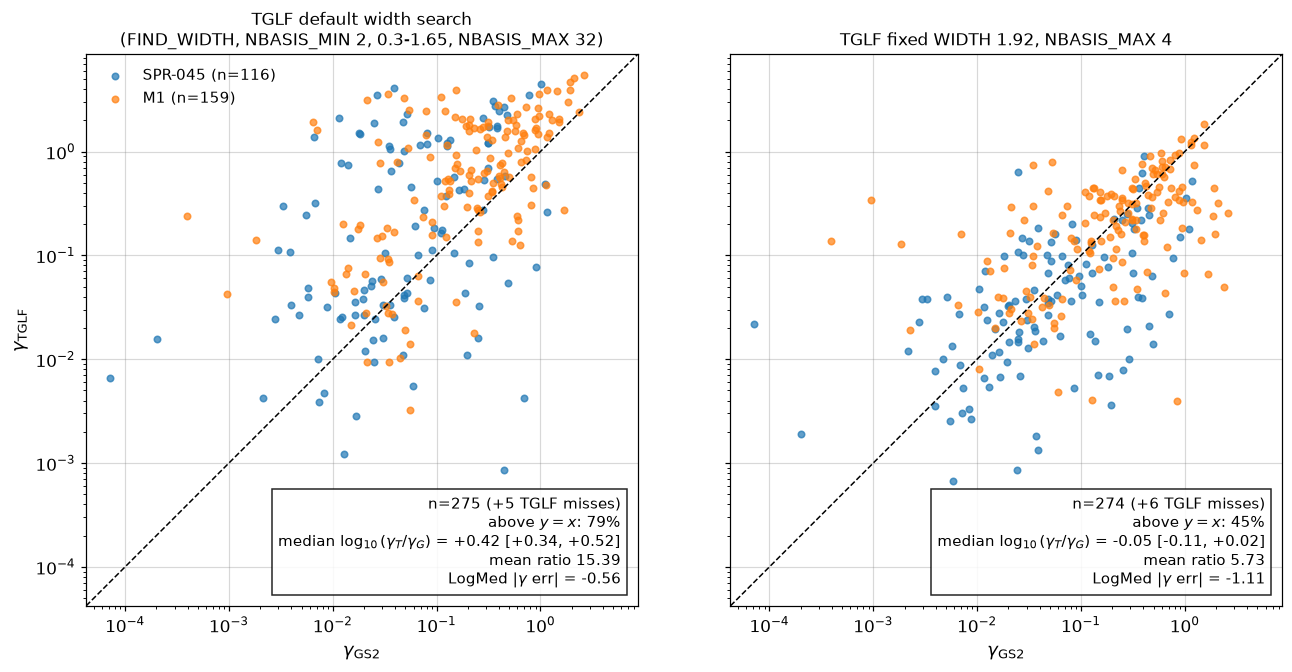

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, (arm, store) in zip(axes, arms.items()):
    for database in databases:
        found = store[database]["gamma"] > 0
        ax.scatter(gs2[database]["gamma"][found], store[database]["gamma"][found], s=18, alpha=0.7, color=colour[database],
                   label=f"{database} (n={found.sum()})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$\gamma_{\rm GS2}$"); ax.set_title(arm, fontsize=11)
    stats = summary[(summary.arm == arm.split("\n")[0]) & (summary.population == "both")].iloc[0]
    ax.text(0.97, 0.03, f"n={stats.n_found} (+{stats.n_miss} TGLF misses)\nabove $y=x$: {100*stats.frac_above:.0f}%\n"
            f"median $\\log_{{10}}(\\gamma_T/\\gamma_G)$ = {stats.median_log_ratio:+.2f} [{stats.ci_lo:+.2f}, {stats.ci_hi:+.2f}]\n"
            f"mean ratio {stats.mean_ratio:.2f}\nLogMed $|\\gamma$ err$|$ = {stats.logmed_abs_err:.2f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=10, bbox=dict(fc="white", alpha=0.85))
axes[0].set_ylabel(r"$\gamma_{\rm TGLF}$")
low = min(ax.get_xlim()[0] for ax in axes); high = max(ax.get_xlim()[1] for ax in axes)
low = min(low, axes[0].get_ylim()[0]); high = max(high, axes[0].get_ylim()[1])
for ax in axes:
    ax.plot([low, high], [low, high], "k--", lw=1); ax.set_xlim(low, high); ax.set_ylim(low, high); ax.set_aspect("equal")
axes[0].legend(loc="upper left")
Path("plots").mkdir(exist_ok=True)
fig.savefig("plots/fig1_tglf_vs_gs2_gamma_search_vs_fixed.png", dpi=200, bbox_inches="tight")

In [5]:
# does over-prediction come with narrow selected widths? threshold = the fixed-width optimum window's lower edge, 1.9
rows = []
for database in databases:
    width = tglf_search[database]["width"]; gamma = tglf_search[database]["gamma"]
    for name, mask in (("narrower than 1.92", width < width_fixed), ("not narrower", width >= width_fixed)):
        keep = mask & (gamma > 0)
        if keep.sum() > 1:
            rows.append(dict(population=database, selected_width=name, **bias_stats(gamma[keep], gs2[database]["gamma"][keep])))
split = pd.DataFrame(rows)
print(split.round(3).to_string())
for database in databases:
    print(database, "selected width quantiles (10/50/90):", np.percentile(tglf_search[database]["width"], [10, 50, 90]).round(2))
summary.to_csv("plots/bias_summary.csv", index=False); split.to_csv("plots/bias_by_selected_width.csv", index=False)

  population      selected_width    n  n_found  n_miss  frac_above  median_log_ratio  ci_lo  ci_hi  mean_ratio  logmed_abs_err
0    SPR-045  narrower than 1.92  116      116       0       0.724             0.484  0.306  0.650      16.649          -0.718
1         M1  narrower than 1.92  159      159       0       0.836             0.400  0.315  0.502      14.477          -0.407
SPR-045 selected width quantiles (10/50/90): [0.3  0.39 1.56]
M1 selected width quantiles (10/50/90): [0.3  0.44 1.33]
